In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

PROJET = Path("/content/drive/MyDrive/MiniProjet-Rétinographie")
PROCESSED = PROJET / "dataset/processed"
DOSSIER_EVALUATION = PROJET / "results/evaluation"

DOSSIER_EVALUATION.mkdir(parents=True, exist_ok=True)

with np.load(PROCESSED / "validation.npz") as donnees:
    X_val = donnees["X"]
    Y_val = donnees["Y"][..., 0].astype(bool)
    FOV_val = donnees["FOV"][..., 0].astype(bool)

with open(PROCESSED / "preparation.json", encoding="utf-8") as fichier:
    configuration = json.load(fichier)

noms = configuration["validation"]

assert len(noms) == len(X_val) == len(Y_val) == len(FOV_val)

print("Images de validation :", noms)
print("Dimensions :", X_val.shape)

Mounted at /content/drive
Images de validation : ['36_training.tif', '30_training.tif', '35_training.tif', '28_training.tif']
Dimensions : (4, 512, 512, 3)


In [2]:
model = tf.keras.models.load_model(
    str(PROJET / "models/meilleur_unet.keras"),
    compile=False
)

probas = model.predict(X_val, batch_size=2)[..., 0]

assert probas.shape == Y_val.shape

print("Prédictions terminées :", probas.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
Prédictions terminées : (4, 512, 512)


In [3]:
def calculer_scores(vrai, predit, champ):
    vrai = vrai[champ]
    predit = predit[champ]

    tp = np.count_nonzero(vrai & predit)
    fp = np.count_nonzero(~vrai & predit)
    fn = np.count_nonzero(vrai & ~predit)

    def division(a, b):
        return float(a / b) if b else np.nan

    return {
        "Dice": division(2 * tp, 2 * tp + fp + fn),
        "IoU": division(tp, tp + fp + fn),
        "Sensibilite": division(tp, tp + fn),
        "Precision": division(tp, tp + fp)
    }


def evaluer_seuil(seuil):
    lignes = []

    for i, nom in enumerate(noms):
        scores = calculer_scores(
            Y_val[i],
            probas[i] >= seuil,
            FOV_val[i]
        )

        lignes.append({"Image": nom, **scores})

    return pd.DataFrame(lignes)


scores_reference = evaluer_seuil(0.5)

display(scores_reference.round(4))
print("\nMoyennes :")
print(scores_reference.select_dtypes("number").mean().round(4))

scores_reference.to_csv(
    DOSSIER_EVALUATION / "scores_validation_seuil_050.csv",
    index=False
)

,Image,Dice,IoU,Sensibilite,Precision
0,36_training.tif,0.7714,0.6278,0.7659,0.7769
1,30_training.tif,0.7275,0.5717,0.6528,0.8215
2,35_training.tif,0.7664,0.6213,0.8142,0.7240
3,28_training.tif,0.7705,0.6267,0.7316,0.8139



Moyennes :
Dice           0.7589
IoU            0.6119
Sensibilite    0.7411
Precision      0.7841
dtype: float64


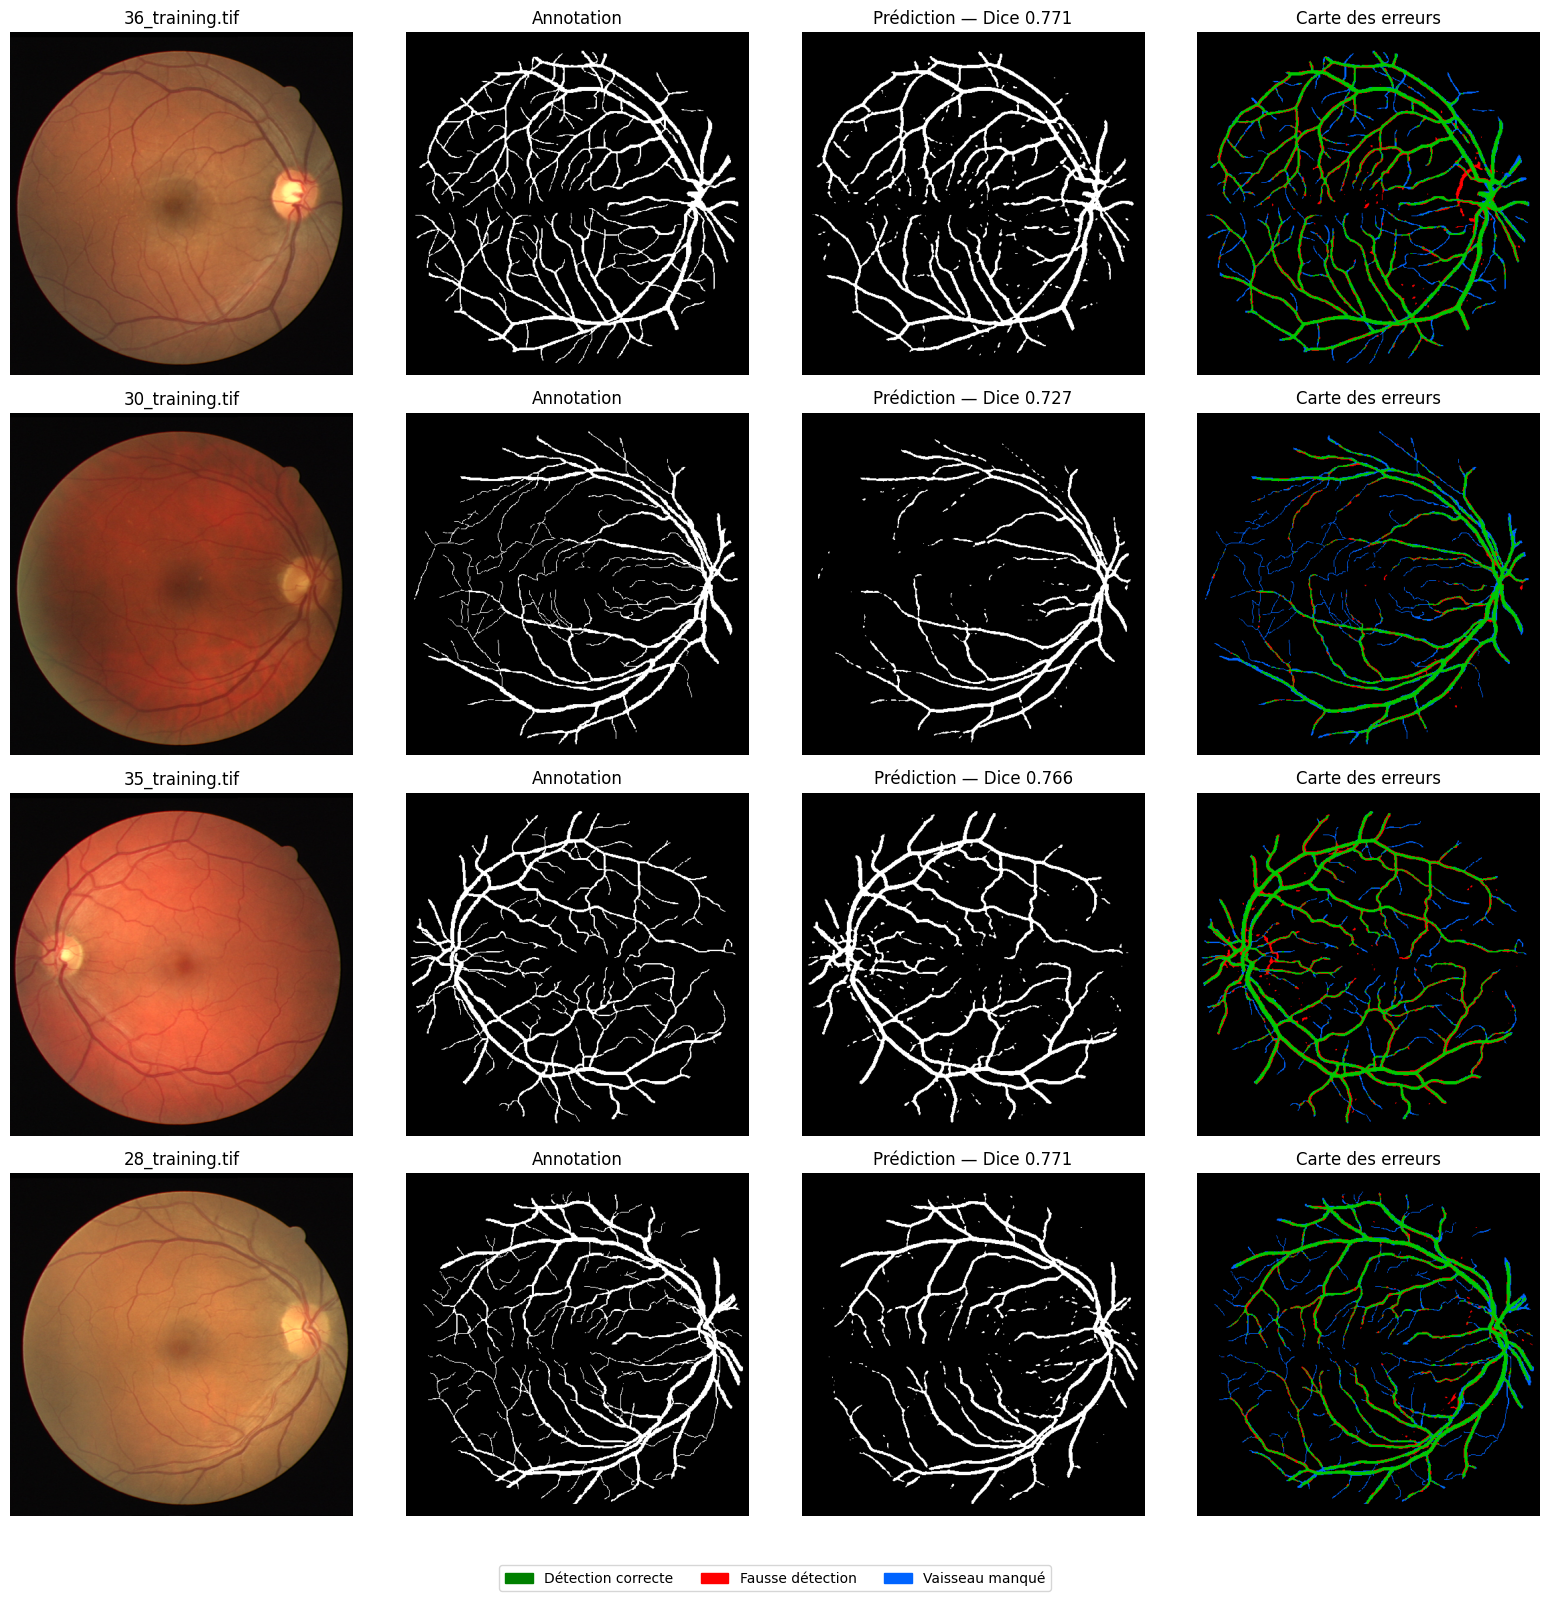

In [4]:
from matplotlib.patches import Patch

SEUIL_REFERENCE = 0.5

fig, axes = plt.subplots(
    len(noms), 4,
    figsize=(16, 4 * len(noms)),
    squeeze=False
)

for i, nom in enumerate(noms):
    vrai = Y_val[i]
    champ = FOV_val[i]
    predit = (probas[i] >= SEUIL_REFERENCE) & champ

    correct = vrai & predit & champ
    faux_positif = ~vrai & predit & champ
    manque = vrai & ~predit & champ

    carte = np.zeros((*vrai.shape, 3), dtype=np.uint8)
    carte[correct] = [0, 200, 0]
    carte[faux_positif] = [255, 0, 0]
    carte[manque] = [0, 100, 255]

    axes[i, 0].imshow(X_val[i])
    axes[i, 0].set_title(nom)

    axes[i, 1].imshow(vrai & champ, cmap="gray")
    axes[i, 1].set_title("Annotation")

    axes[i, 2].imshow(predit, cmap="gray")
    axes[i, 2].set_title(
        f"Prédiction — Dice {scores_reference.iloc[i]['Dice']:.3f}"
    )

    axes[i, 3].imshow(carte)
    axes[i, 3].set_title("Carte des erreurs")

for ax in axes.ravel():
    ax.axis("off")

legende = [
    Patch(color="green", label="Détection correcte"),
    Patch(color="red", label="Fausse détection"),
    Patch(color="#0064ff", label="Vaisseau manqué")
]

fig.legend(handles=legende, loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    DOSSIER_EVALUATION / "cartes_erreurs_validation.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

,Seuil,Dice,IoU,Sensibilite,Precision
0,0.2,0.7512,0.6017,0.8127,0.7013
1,0.3,0.7578,0.6102,0.7861,0.7353
2,0.4,0.7600,0.6131,0.7637,0.7613
3,0.5,0.7589,0.6119,0.7411,0.7841
4,0.6,0.7549,0.6069,0.7173,0.8047
5,0.7,0.7481,0.5985,0.6907,0.8260
6,0.8,0.7365,0.5846,0.6568,0.8518


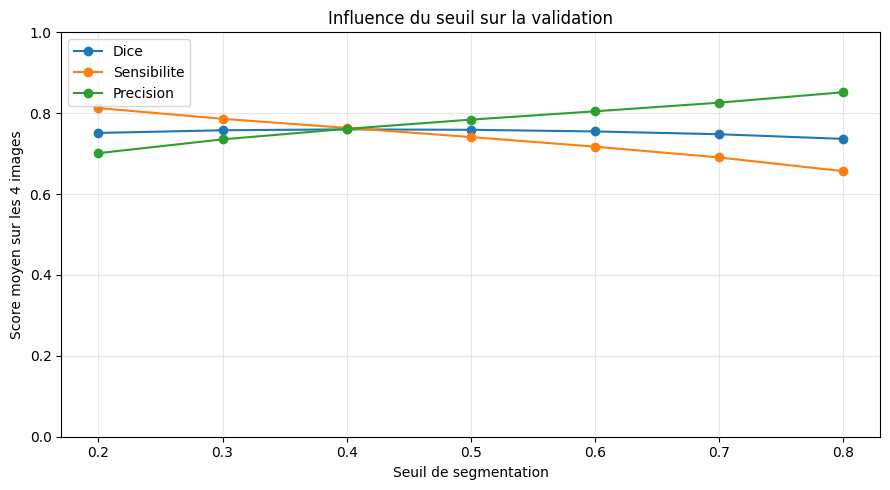

In [5]:
seuils = np.round(np.arange(0.2, 0.81, 0.1), 2)
comparaisons = []

for seuil in seuils:
    tableau = evaluer_seuil(float(seuil))
    moyennes = tableau.select_dtypes("number").mean()

    comparaisons.append({
        "Seuil": float(seuil),
        **moyennes.to_dict()
    })

comparaison = pd.DataFrame(comparaisons)

display(comparaison.round(4))

comparaison.to_csv(
    DOSSIER_EVALUATION / "comparaison_seuils_validation.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

for metrique in ["Dice", "Sensibilite", "Precision"]:
    ax.plot(
        comparaison["Seuil"],
        comparaison[metrique],
        marker="o",
        label=metrique
    )

ax.set_xlabel("Seuil de segmentation")
ax.set_ylabel("Score moyen sur les 4 images")
ax.set_title("Influence du seuil sur la validation")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    DOSSIER_EVALUATION / "influence_seuil.png",
    dpi=180
)
plt.show()

In [6]:
meilleur = comparaison.loc[comparaison["Dice"].idxmax()]
seuil_selectionne = float(meilleur["Seuil"])

dice_initial = float(scores_reference["Dice"].mean())
dice_selectionne = float(meilleur["Dice"])

print("Seuil sélectionné sur la validation :", seuil_selectionne)
print(f"Dice au seuil 0,5 : {dice_initial:.4f}")
print(f"Dice au seuil sélectionné : {dice_selectionne:.4f}")
print(f"Différence : {dice_selectionne - dice_initial:+.4f}")

scores_selectionnes = evaluer_seuil(seuil_selectionne)

scores_selectionnes.to_csv(
    DOSSIER_EVALUATION / "scores_validation_seuil_selectionne.csv",
    index=False
)

with open(
    DOSSIER_EVALUATION / "seuil_selectionne.json",
    "w",
    encoding="utf-8"
) as fichier:
    json.dump({
        "seuil": seuil_selectionne,
        "critere": "Dice moyen dans le champ rétinien",
        "donnees": "4 images de validation",
        "seuils_essayes": seuils.tolist(),
        "dice_reference_050": dice_initial,
        "dice_validation_selection": dice_selectionne
    }, fichier, indent=2, ensure_ascii=False)

Seuil sélectionné sur la validation : 0.4
Dice au seuil 0,5 : 0.7589
Dice au seuil sélectionné : 0.7600
Différence : +0.0011


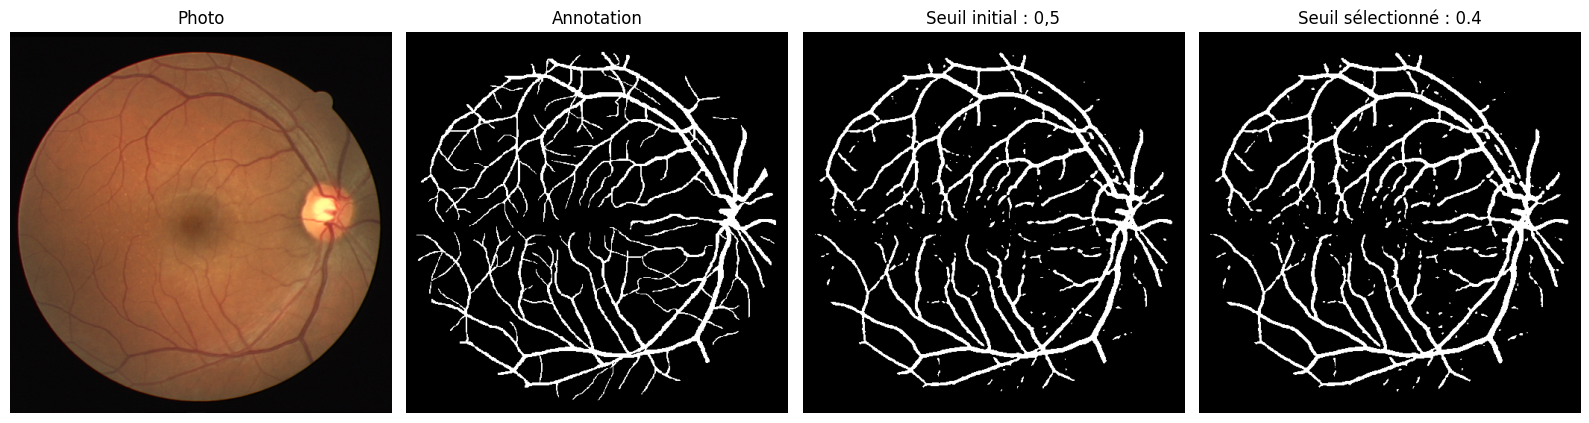

In [7]:
i = 0  # Choisir 0, 1, 2 ou 3

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

elements = [
    (X_val[i], "Photo"),
    (Y_val[i] & FOV_val[i], "Annotation"),
    (
        (probas[i] >= 0.5) & FOV_val[i],
        "Seuil initial : 0,5"
    ),
    (
        (probas[i] >= seuil_selectionne) & FOV_val[i],
        f"Seuil sélectionné : {seuil_selectionne:.1f}"
    )
]

for ax, (image, titre) in zip(axes, elements):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    DOSSIER_EVALUATION / "comparaison_visuelle_seuils.png",
    dpi=180
)
plt.show()

# Évaluation et visualisation des résultats de U-Net

## Objectif
Ce notebook analyse les performances du modèle U-Net déjà entraîné
pour la segmentation des vaisseaux rétiniens. Il recharge le modèle
sauvegardé et les quatre images de validation, sans nouvel entraînement.

## Méthode
L’évaluation est réalisée sur les images redimensionnées en 512 × 512
pixels, uniquement à l’intérieur du champ rétinien. Les probabilités
produites par U-Net sont transformées en masques binaires à l’aide
d’un seuil, initialement fixé à 0,5.

Quatre métriques sont calculées :
- **Dice** : mesure le recouvrement entre la prédiction et l’annotation.
- **IoU** : rapporte leur intersection à leur union.
- **Sensibilité** : mesure la proportion des pixels de vaisseaux retrouvés.
- **Précision** : mesure la proportion des pixels détectés qui correspondent
  réellement aux vaisseaux annotés.

Les scores sont calculés pour chaque image, puis moyennés.

## Analyse visuelle
Les cartes d’erreurs distinguent :
- en vert, les vaisseaux correctement détectés ;
- en rouge, les fausses détections ;
- en bleu, les vaisseaux manqués.

Elles permettent de localiser les erreurs et d’examiner notamment
la détection des petits vaisseaux.

## Influence du seuil
Plusieurs seuils, de 0,2 à 0,8, sont comparés pour observer le compromis
entre sensibilité et précision. Le seuil donnant le meilleur Dice moyen
sur la validation est retenu parmi les valeurs essayées.

## Limites
Les quatre images de validation ont servi à sélectionner le modèle
et à comparer les seuils. Les scores obtenus ne constituent donc pas
une évaluation indépendante sur le test.

Les annotations manuelles des vaisseaux du test étant absentes de notre
copie de la base, ses performances quantitatives ne sont pas calculées.

Les tableaux et figures sont sauvegardés dans `results/evaluation`
pour le rapport et le dépôt GitHub.